## Data Anaysis of the FMA dataset 

### Contents of the Dataset : 
For each datapoint consists of an audio track

$\mathbb{D}_{fma} = \{x_i\}_{i=1}^{N}$



Where : 
- $x_i$ is the MP3 audio sample 

In [3]:
# Imports
import pandas as pd
import random as r
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def add_clean_track_id(
        df : pd.DataFrame) -> pd.DataFrame:
    '''
    Creating an systamic version of track_id and mark which rows are vaild 
    by removing any nan values, and condesning duplicate rows. 

    Args: 
        df : pd.DataFrame -> The csv file loaded into a dataframe
    
    Returns:
        df : pd.DataFrame -> Modified dataframe with added coloums of 
        track_id_clean and is_valid_dataset
    '''

    if "track_id" not in df.columns:
        raise KeyError("KeyError : Missing Key track_id, check the dataframes colums")
    
    df = df.copy()

    df["track_id_clean"] = pd.to_numeric(
        df["track_id"],
        errors= "coerce",
    ).astype("Int64")
    df["is_valid_track_id"] = df["track_id_clean"].notna()

    return df

In [5]:
def split_duplicates(
        df: pd.DataFrame, 
        subset: list[str] | None = None) -> tuple[pd.DataFrame,pd.DataFrame]:
    '''
    Extracting the duplicates from the dataset

    Args: 
        df : pd.DataFrame -> The dataframe
        subset : list[str] | None = None -> Coloums to use as a key to identify duplicates

    Return: 
        unique_rows : pd.DataFrame -> A dataset with only unqiue_rows
    '''

    mask = df.duplicated(subset=subset, keep=False)
    
    duplicate_rows = df[mask].copy()
    unique_rows = df[~mask].copy()

    return unique_rows, duplicate_rows

In [6]:
def split_valid_and_quarantine(
        df : pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''
    Divide the rows into two categories: redundant and usable, 
    based on whether track_id_clean is vaild.
    ## Do the Doc string
    '''
    valid_rows = df[df["is_valid_track_id"]].copy()
    quarantine_rows = df[~df["is_valid_track_id"]].copy()

    return valid_rows, quarantine_rows

### Loading the FMA dataset

Reading and cleaning the dataset with the help of `add_clean_track_id` and `split_valid_and_quarantine` funtions. 

```datasets\fma\fma_metadata\modified\track_with_tokens_and_genre.csv```


In [7]:
df = pd.read_csv("../../datasets/fma/fma_metadata/modified/track_with_tokens_and_genre.csv")

C:\Users\rj312\AppData\Local\Temp\ipykernel_23288\2841754875.py:1: DtypeWarning: Columns (20,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../../datasets/fma/fma_metadata/modified/track_with_tokens_and_genre.csv")


In [8]:
print(f"{df.shape=}\n" \
f"{df.columns.tolist()=}\n"\
f"{df.isnull().sum()=}")

df.shape=(136641, 25)
df.columns.tolist()=['track_id', 'track_title', 'artist_name', 'artist_bio', 'track_tags', 'genres_all', 'genre_top', 'listens', 'favorites', 'track_info', 'date_released', 'date_recorded', 'tags_list', 'genres_all_ids', 'date_released_year', 'date_recorded_year', 'z_listens', 'z_favorites', 'listen_tier', 'favorite_tier', 'genre_top_name', 'genre_parent_name', 'genre_top_level_name', 'genre_all_names', 'genre_word_tokens']
df.isnull().sum()=track_id                    88
track_title              30237
artist_name              29959
artist_bio               65140
track_tags               29254
genres_all               30047
genre_top                87003
listens                      0
favorites                    0
track_info               51681
date_released            58693
date_recorded           129784
tags_list                    0
genres_all_ids               0
date_released_year      104213
date_recorded_year      130487
z_listens                    0
z_fav

In [9]:
df = add_clean_track_id(df)
valid_rows, quarantine_rows = split_valid_and_quarantine(df)

unique_rows, duplicate_rows = split_duplicates(
    valid_rows,
    subset=["track_title"]
)

In [10]:
# Check
i = r.randint(1,len(unique_rows))
unique_rows[i:i+2]

,track_id,track_title,artist_name,artist_bio,track_tags,genres_all,genre_top,listens,favorites,track_info,...,z_favorites,listen_tier,favorite_tier,genre_top_name,genre_parent_name,genre_top_level_name,genre_all_names,genre_word_tokens,track_id_clean,is_valid_track_id
124059,140418,Bunk Beds,Ennio the Little Brother,NaN,[],[],NaN,-1,-1,NaN,...,-0.294693,typical,typical,NaN,NaN,NaN,[],[],140418,True
124103,140503,Thee First Transmission,Ars Sonor,"One-woman project, producing imaginative textu...",[],"[181, 38, 15]",NaN,-1,-1,NaN,...,-0.294693,typical,typical,NaN,NaN,NaN,"['Techno', 'Experimental', 'Electronic']","['techno', 'experimental', 'electronic']",140503,True


In [11]:
print(f"{unique_rows.shape=}\n" \
f"{unique_rows.columns.tolist()=}\n"\
f"{unique_rows.isnull().sum()=}")

unique_rows.shape=(2558, 27)
unique_rows.columns.tolist()=['track_id', 'track_title', 'artist_name', 'artist_bio', 'track_tags', 'genres_all', 'genre_top', 'listens', 'favorites', 'track_info', 'date_released', 'date_recorded', 'tags_list', 'genres_all_ids', 'date_released_year', 'date_recorded_year', 'z_listens', 'z_favorites', 'listen_tier', 'favorite_tier', 'genre_top_name', 'genre_parent_name', 'genre_top_level_name', 'genre_all_names', 'genre_word_tokens', 'track_id_clean', 'is_valid_track_id']
unique_rows.isnull().sum()=track_id                   0
track_title                0
artist_name                1
artist_bio               742
track_tags                 0
genres_all                 1
genre_top               1319
listens                    0
favorites                  0
track_info               822
date_released           1247
date_recorded           2283
tags_list                  0
genres_all_ids             0
date_released_year      1884
date_recorded_year      2285
z_li

### Plotting

From the dataset, plots are shown to see how the dataset has been cleaned and refactored

In [12]:
class Plot:
    def __init__(self, df):
        self.df = df

    def _plot_bar(
            self,
            counts: pd.Series,
            title: str,
            xlabel: str = "Category",
            ylabel: str = "Number of Datapoints",
            kind : str = "bar") -> None:
        """
        Plot a bar chart with value labels above each bar.
        """
        ax = counts.plot(kind=kind)

        for i, value in enumerate(counts):
            ax.text(i, value, str(value), ha="center", va="bottom")

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=0)

        snake_case = title.lower().replace(" ", "_")

        plt.savefig( "../../plots/fma/"+ f"{snake_case}.png", dpi=300, bbox_inches="tight")

        plt.tight_layout()
        plt.show()

    def _plot_distribution(
            self,
            col: str,
            bins: int = 50,
            hist: bool = False,
            prob_dist: bool = False) -> None:
        
        data = self.df[col].dropna()
        
        if prob_dist == True:
            data = (data - data.min()) / (data.max() - data.min())

        mu = data.mean()
        sigma = data.std()

        plt.figure(figsize=(10,6))

        if hist == True: 
            plt.hist(data, bins=bins, density=True, alpha=0.7)

        x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)

        gaussian = (
            1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
                -0.5 * ((x - mu) / sigma) ** 2
            )
        
        label_case = col.replace("_", " ").title()

        if prob_dist == True:
            label_case += " (Scaled to 0 - 1)"


        plt.plot(x, gaussian, label=fr"$\mu={mu:.3f},\ \sigma={sigma:.3f}$")
        plt.title(f"Distribution of {label_case}")
        label_case = label_case.replace(" (Scaled to 0 - 1)", "")
        plt.xlabel(label_case)
        plt.ylabel("Density")
        plt.legend()


        snake_case = f"inference_distribution_of_{col}".lower().replace(" ", "_")

        plt.tight_layout()
        plt.savefig(
            f"..\\..\\plots\\fma\\dataset\\{snake_case}.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
    
    def valid_vs_quarantine(self, kind):
        counts = self.df["is_valid_track_id"].value_counts().rename(
            {
                True: "Valid",
                False: "Quarantine"
            }
        )
        self._plot_bar(counts, title="Valid vs Quarantine Tracks")

    def unique_vs_duplicate(
            self,
            kind, 
            subset: list[str] | None = None, ) -> None:
        unique_rows, duplicate_rows = split_duplicates(self.df, subset=subset)

        counts = pd.Series(
            {
                "Unique": len(unique_rows),
                "Duplicate": len(duplicate_rows)
            }
        )

        self._plot_bar(counts, title="Unique vs Duplicate Rows")

    def valence_pred_dist(self, col : str, hist: bool = True, prob_dist : bool = False) -> None: self._plot_distribution(col=col, hist=hist, prob_dist=prob_dist)

    def arousal_pred_dist(self, col : str, hist: bool = True, prob_dist : bool = False) -> None: self._plot_distribution(col=col, hist=hist, prob_dist=prob_dist)

    def dominance_pred_dist(self, col : str, hist: bool = True, prob_dist : bool = False) -> None: self._plot_distribution(col=col, hist=hist, prob_dist=prob_dist)
        
        


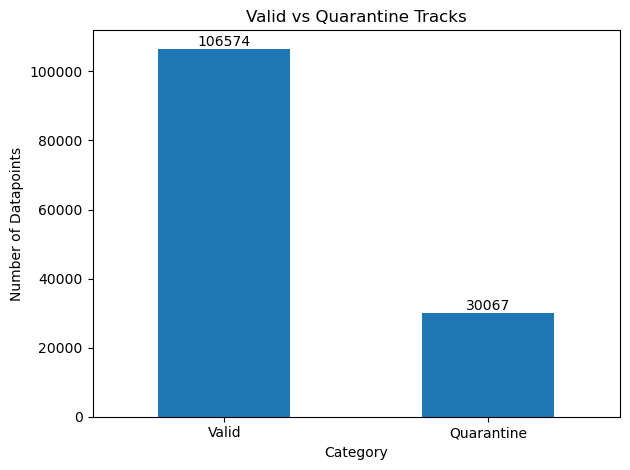

In [13]:
plot = Plot(df)
plot.valid_vs_quarantine("bar")

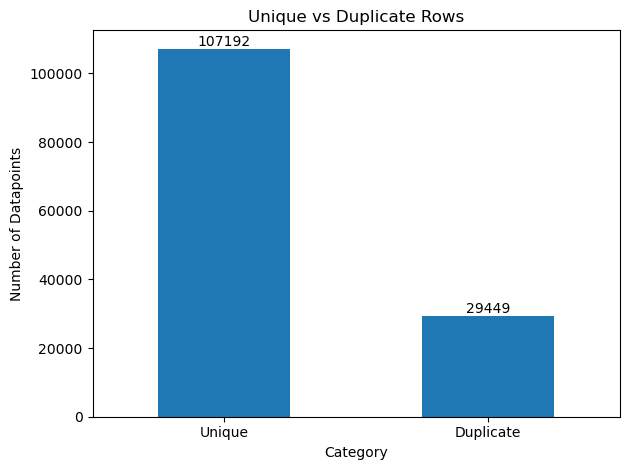

In [14]:
plot.unique_vs_duplicate("bar")

### Prompt Builder

In [15]:
fma_prompt_df = unique_rows[
    ["track_id", "track_title", "artist_name", "genre_all_names", "track_tags"]
].copy()

fma_prompt_df["prompt"] = (
    "Track: " + unique_rows["track_title"].fillna("").astype(str) +
    " | Artist: " + unique_rows["artist_name"].fillna("").astype(str) +
    " | Genres: " + unique_rows["genre_all_names"].fillna("").astype(str) +
    " | Tags: " + unique_rows["track_tags"].fillna("").astype(str)
)

In [ ]:
fma_full_prompt_df = df[
    ["track_id", "track_title", "artist_name", "genre_all_names", "track_tags"]
].copy()

fma_prompt_df["prompt"] = (
    "Track: " + unique_rows["track_title"].fillna("").astype(str) +
    " | Artist: " + unique_rows["artist_name"].fillna("").astype(str) +
    " | Genres: " + unique_rows["genre_all_names"].fillna("").astype(str) +
    " | Tags: " + unique_rows["track_tags"].fillna("").astype(str)
)

In [16]:
fma_prompt_df[:3]

,track_id,track_title,artist_name,genre_all_names,track_tags,prompt
15,140,The Blind Spot,Alec K. Redfearn & the Eyesores,['Folk'],[],Track: The Blind Spot | Artist: Alec K. Redfea...
17,142,The Quiet Room,Alec K. Redfearn & the Eyesores,['Folk'],[],Track: The Quiet Room | Artist: Alec K. Redfea...
22,148,Contradiction,Contradiction,"['Avant-Garde', 'Experimental']",[],Track: Contradiction | Artist: Contradiction |...


In [17]:
fma_prompt_df.to_csv("..\\..\\datasets\\fma\\fma_metadata\\modified\\bert_prompt_df.csv", index=False)
fma_prompt_df.to_parquet("..\\..\\datasets\\fma\\fma_metadata\\modified\\bert_prompt_df.parquet", index=False)

### Post Inference

In [18]:
vad_df = pd.read_csv("../../datasets\\fma\\fma_metadata\\modified\\fma_vad_predictions.csv")

inference_plot = Plot(vad_df)

In [19]:
print(vad_df["valence_pred"].min())
print(vad_df["valence_pred"].max())

3.341581344604492
4.3625359535217285


In [20]:
valence_min = vad_df["valence_pred"].min()
valence_max = vad_df["valence_pred"].max()

arousal_min = vad_df["arousal_pred"].min()
arousal_max = vad_df["arousal_pred"].max()

dominance_min = vad_df["dominance_pred"].min()
dominance_max = vad_df["dominance_pred"].max()


vad_df["valence_pred"] = (
    vad_df["valence_pred"] * (valence_max - valence_min)
) + valence_min

vad_df["arousal_pred"] = (
    vad_df["arousal_pred"] * (arousal_max - arousal_min)
) + arousal_min

vad_df["dominance_pred"] = (
    vad_df["dominance_pred"] * (dominance_max - dominance_min)
) + dominance_min

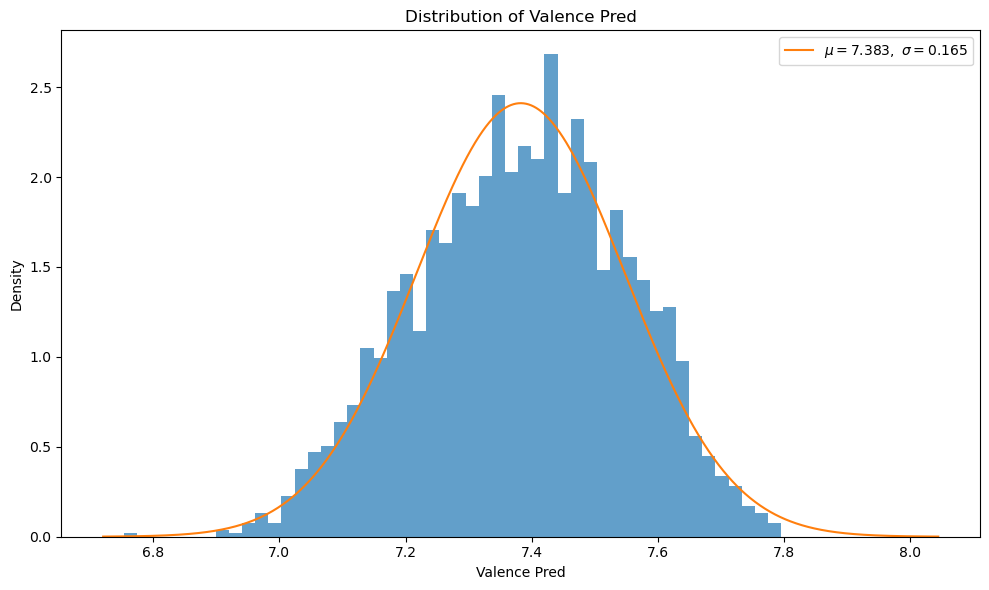

In [21]:
inference_plot.valence_pred_dist(col="valence_pred",prob_dist=False)

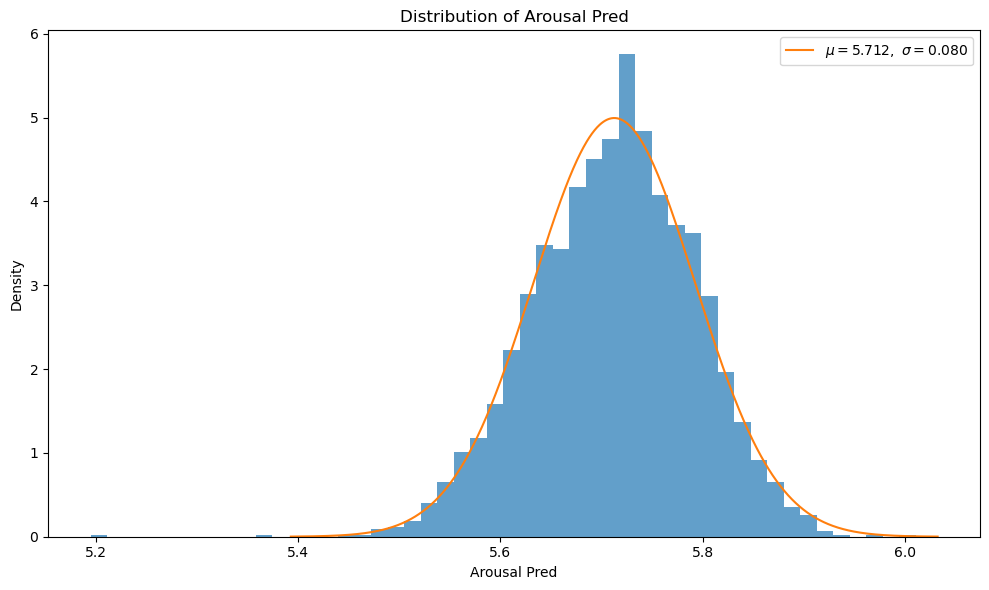

In [22]:
inference_plot.arousal_pred_dist(col="arousal_pred",prob_dist=False)

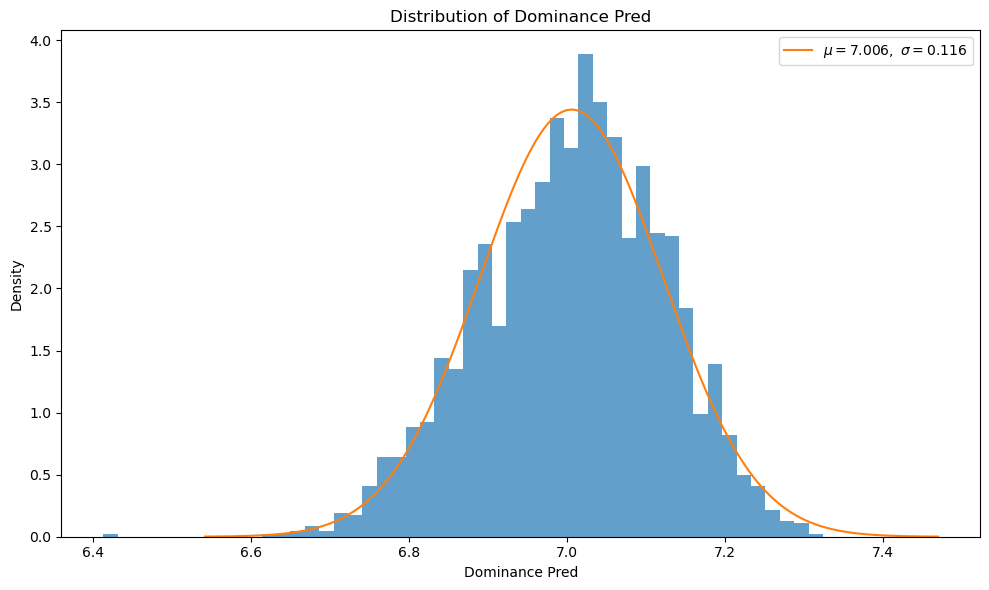

In [23]:
inference_plot.dominance_pred_dist(col="dominance_pred",prob_dist=False)